In [1]:
import os, re, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY = "#335295", "#B7791F", "#9BB0DB"

# ---------------- CONFIG: only edit DATA_DIR ----------------
SEED = 42
DATA_DIR = Path(os.environ.get("EV_DATA_DIR", r"D:\Dharini\Capstone"))   # folder containing Power Consumption/, Host Events/, Network Traffic/
NET_CAP_PER_CLASS = 6000      # network flows sampled per attack type per device (keeps the run short)
MIN_CLASS = 200               # network classes with fewer sampled flows are not modelled
RF_TREES = 150
BLOCK = {"power": 500, "host": 50, "net": 2000}
FILES = {"power": DATA_DIR/"Power Consumption"/"EVSE-B-PowerCombined.csv",
         "host":  DATA_DIR/"Host Events"/"EVSE-B-HPC-Kernel-Events-Combined.csv"}
NET_DIRS = {"netA": DATA_DIR/"Network Traffic"/"EVSE-A", "netB": DATA_DIR/"Network Traffic"/"EVSE-B"}
NET_COMBINED_DIR = Path(os.environ.get("EV_NET_COMBINED_DIR", DATA_DIR/"Network Traffic"))   # where EVSE-A/B-Network-Combined.csv live (used if present)
NET_COMBINED = {"netA": NET_COMBINED_DIR/"EVSE-A-Network-Combined.csv", "netB": NET_COMBINED_DIR/"EVSE-B-Network-Combined.csv"}
for k, p in FILES.items(): print(f"{k:6s}", "FOUND" if p.is_file() else "MISSING", p)
for k in NET_DIRS: print(f"{k:6s}", "combined file FOUND" if NET_COMBINED[k].is_file() else ("per-scenario CSVs FOUND" if (NET_DIRS[k]/"csv").is_dir() else "MISSING"), NET_COMBINED[k] if NET_COMBINED[k].is_file() else NET_DIRS[k])

power  FOUND D:\Dharini\Capstone\Power Consumption\EVSE-B-PowerCombined.csv
host   FOUND D:\Dharini\Capstone\Host Events\EVSE-B-HPC-Kernel-Events-Combined.csv
netA   per-scenario CSVs FOUND D:\Dharini\Capstone\Network Traffic\EVSE-A
netB   per-scenario CSVs FOUND D:\Dharini\Capstone\Network Traffic\EVSE-B


## 1. Load and clean the data


In [2]:
NAME_FIX = {"serice-detection":"service-detection","icmp-fragmentation_old":"icmp-fragmentation","os-scan":"os-fingerprinting",
            "none":"benign","0":"benign","portscan":"port-scan","service-detection-scan":"service-detection","slowloris-scan":"slowloris",
            "syn-stealth-scan":"syn-stealth","synonymous-ip":"synonymous-ip-flood","vulnerability-scan":"vuln-scan",
            "agressive-scan":"aggressive-scan","tcp-port-scan":"port-scan","service-version-detection":"service-detection",
            "os-fingerpriting":"os-fingerprinting","upd-flood":"udp-flood","pshack-flood":"push-ack-flood","synonymousip-flood":"synonymous-ip-flood",
            "vulnerability-scan":"vuln-scan"}
GROUP = {"benign":"none","port-scan":"recon","vuln-scan":"recon","syn-stealth":"recon","aggressive-scan":"recon","service-detection":"recon",
         "os-fingerprinting":"recon","slowloris":"DoS","icmp-flood":"DoS","push-ack-flood":"DoS","syn-flood":"DoS","tcp-flood":"DoS",
         "synonymous-ip-flood":"DoS","udp-flood":"DoS","icmp-fragmentation":"DoS","cryptojacking":"host-attack","backdoor":"host-attack"}
norm = lambda s: s.astype("string").str.strip().str.lower().replace(NAME_FIX)
def segment_ids(attack, state):   # recordings = runs of identical (attack, state)
    k = pd.Series(np.asarray(attack)).astype(str) + "|" + pd.Series(np.asarray(state)).astype(str)
    return (k != k.shift()).cumsum().values
CLEAN = []
def log(m): CLEAN.append(m)

# ---- POWER (EVSE-B) ----
power = pd.read_csv(FILES["power"], low_memory=False)   # note: the text "None" in Attack is read as missing -> filled below as benign
power["attack_norm"] = norm(power["Attack"].fillna("none")); power["group"] = power["Attack-Group"].fillna("none").astype("string").str.strip().replace({"dos":"DoS","None":"none","NONE":"none"})
power["is_attack"] = (power["Label"].astype("string").str.lower() == "attack").astype(int)
power["state_charging"] = (power["State"].astype("string").str.lower() == "charging").astype(int)
power["row_no"] = np.arange(len(power)); power["rec"] = segment_ids(power["attack_norm"], power["state_charging"])
POWER_FEATS = ["shunt_voltage","bus_voltage_V","current_mA","power_mW","state_charging"]
log(f"Power: {len(power):,} rows kept; exact duplicates kept (minute-level timestamps, repeated 1-s sensor readings are plausible).")

# ---- HOST (EVSE-B): repair the stacked file ----
hr = pd.read_csv(FILES["host"], low_memory=False)
unn = [c for c in hr.columns if str(c).startswith("Unnamed:")]
meta = ["State","Attack","Scenario","Label","interface"] + unn
cnt = [c for c in hr.columns if c not in meta and c != "time"]
b2 = (hr[unn[0]].notna() & (hr[unn[0]].astype("string") != "Attack")) if unn else pd.Series(False, index=hr.index)
attack_raw = hr["Attack"].where(~b2, hr[unn[0]]) if unn else hr["Attack"]
state_raw  = hr["State"].where(~b2, hr["interface"])
Xh = hr[cnt].apply(pd.to_numeric, errors="coerce"); valid = Xh.notna().mean(axis=1) > 0.5
host = pd.DataFrame({"attack_norm": norm(attack_raw.fillna("none"))[valid].values, "state": state_raw.astype("string")[valid].values, "block2": b2[valid].values})
host["is_attack"] = (host["attack_norm"] != "benign").astype(int); host["group"] = host["attack_norm"].map(GROUP).fillna("unmapped")
X_host = Xh[valid].reset_index(drop=True); const = [c for c in X_host if X_host[c].nunique(dropna=True) <= 1]; X_host = X_host.drop(columns=const)
host["row_no"] = np.arange(len(host)); host["rec"] = segment_ids(host["attack_norm"], host["state"].astype(str)+"|"+host["block2"].astype(str))
log(f"Host: {len(hr):,} raw rows -> {int(valid.sum()):,} usable ({int((~valid).sum())} blank/header rows dropped); {len(const)} constant columns dropped; {X_host.shape[1]} features remain.")

# ---- NETWORK (EVSE-A, EVSE-B) ----
NET_EXCL = {"id","expiration_id","src_ip","src_mac","src_oui","src_port","dst_ip","dst_mac","dst_oui","vlan_id","tunnel_id",
 "bidirectional_first_seen_ms","bidirectional_last_seen_ms","src2dst_first_seen_ms","src2dst_last_seen_ms","dst2src_first_seen_ms","dst2src_last_seen_ms",
 "application_name","application_category_name","requested_server_name","client_fingerprint","server_fingerprint","user_agent","content_type",
 "device","State","Attack","Attack-Group","Label","source_file"}
def load_net(key):
    """Uses EVSE-x-Network-Combined.csv (read in chunks, class-capped sample) if present, else the per-scenario CSVs."""
    comb = NET_COMBINED[key]
    if comb.is_file():
        rng = np.random.default_rng(SEED); hdr = pd.read_csv(comb, nrows=0).columns; feats0 = [c for c in hdr if c not in NET_EXCL]
        parts, off = [], 0
        for ch in pd.read_csv(comb, usecols=feats0+["Attack","source_file"], chunksize=250_000, low_memory=False):
            ch["row_no"] = np.arange(off, off+len(ch)); off += len(ch)
            a = ch["Attack"].fillna("none").astype("string"); rank = pd.Series(rng.random(len(ch)), index=ch.index).groupby(a).rank(method="first")
            parts.append(ch[rank <= 4000])
        df = pd.concat(parts, ignore_index=True); df["attack_norm"] = norm(df["Attack"].fillna("none"))
    else:
        parts = []
        for p in sorted((NET_DIRS[key]/"csv").glob("*.csv")):
            d = pd.read_csv(p, low_memory=False); stem = re.sub(r"^evse-[ab]-(charging|idle|maliciousev)-", "", p.stem.lower())
            d["source_file"] = p.name; d["attack_norm"] = norm(pd.Series([stem]))[0]; d["row_no"] = np.arange(len(d)); parts.append(d)
        df = pd.concat(parts, ignore_index=True)
    df["group"] = df["attack_norm"].map(GROUP).fillna("unmapped")
    df = df.sample(frac=1, random_state=SEED); df = df[df.groupby("attack_norm").cumcount() < NET_CAP_PER_CLASS].sort_values(["source_file","row_no"]).reset_index(drop=True)
    feats = [c for c in df.columns if c not in NET_EXCL and c not in ("attack_norm","group","row_no","Attack")]
    df[feats] = df[feats].apply(pd.to_numeric, errors="coerce"); feats = [c for c in feats if df[c].notna().mean() > 0.5 and df[c].nunique() > 1]
    df["block"] = df["source_file"] + "_" + (df["row_no"] // BLOCK["net"]).astype(str)
    return df, feats
net = {k: load_net(k) for k in NET_DIRS if NET_COMBINED[k].is_file() or (NET_DIRS[k]/"csv").is_dir()}
for k,(df,f) in net.items(): log(f"{k}: {len(df):,} sampled flows from {df.source_file.nunique()} recordings, {len(f)} usable numeric features (IDs/IPs/MACs/timestamps removed).")
print("\n".join("• "+m for m in CLEAN))

• Power: 115,298 rows kept; exact duplicates kept (minute-level timestamps, repeated 1-s sensor readings are plausible).
• Host: 8,474 raw rows -> 8,468 usable (6 blank/header rows dropped); 622 constant columns dropped; 283 features remain.
• netA: 70,301 sampled flows from 28 recordings, 60 usable numeric features (IDs/IPs/MACs/timestamps removed).
• netB: 66,072 sampled flows from 31 recordings, 60 usable numeric features (IDs/IPs/MACs/timestamps removed).


## 2. Dataset overview and class balance

'        source    rows benign  attack  attack_types  attack_%\nPower (EVSE-B) 115,298 14,363 100,935             7      87.5\n Host (EVSE-B)   8,468  2,302   6,166            16      72.8\n     Network A  70,301     82  70,219            15      99.9\n     Network B  66,072      0  66,072            13     100.0'

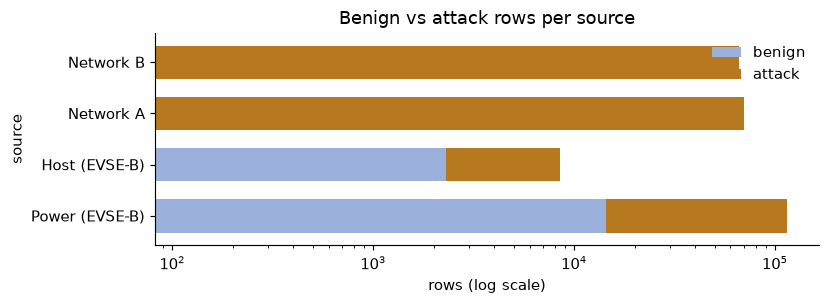

In [3]:
inv = []
for name, d in [("Power (EVSE-B)", power), ("Host (EVSE-B)", host)]:
    inv.append([name, len(d), int((d.is_attack==0).sum()), int((d.is_attack==1).sum()), d.attack_norm.nunique()])
for k,(d,_) in net.items():
    b = int((d.attack_norm=="benign").sum()); inv.append([f"Network {k[-1]}", len(d), b, len(d)-b, d.attack_norm.nunique()])
inv = pd.DataFrame(inv, columns=["source","rows","benign","attack","attack_types"]); inv["attack_%"] = (100*inv.attack/inv.rows).round(1)
display(inv.to_string(
    index=False,
    formatters={
        "rows": lambda x: f"{x:,}",
        "benign": lambda x: f"{x:,}",
        "attack": lambda x: f"{x:,}"
    }
))
ax = inv.set_index("source")[["benign","attack"]].plot.barh(stacked=True, color=[GREY, ORANGE], figsize=(8,3), width=.65)
ax.set_xscale("log"); ax.set_xlabel("rows (log scale)"); ax.set_title("Benign vs attack rows per source"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Takeaway:** the data is heavily imbalanced (little or no benign network traffic), so accuracy alone is misleading. We report **macro-F1** and always compare against a majority-class **Dummy** baseline.

## 3. Evaluation design
Random row splits leak (neighbouring rows of one recording look alike), so three tiers are used, from optimistic to strict:

| Tier | Meaning |
|---|---|
| **Block** | contiguous blocks held out (optimistic upper bound) |
| **Temporal holdout** | tail of each recording held out with a gap; attack recordings with ≥2 repeats held out whole |
| **LORO** | leave-one-recording-out: every recording is the test set once (strictest) |

Models: Dummy (majority), Logistic Regression, Random Forest.

In [4]:
def blocked_split(y, groups, test_size=0.25, tries=60):
    y = pd.Series(np.asarray(y)); best = None
    for i in range(tries):
        tr, te = next(GroupShuffleSplit(1, test_size=test_size, random_state=SEED+i).split(np.zeros(len(y)), groups=np.asarray(groups)))
        best = (tr, te); ct, ce = y.iloc[tr].value_counts(), y.iloc[te].value_counts()
        if all(ct.get(c,0) >= 20 and ce.get(c,0) >= 20 for c in y.value_counts()[lambda s: s>=100].index): return tr, te
    return best
def hybrid_split(y, rec, row_no, tail_frac=0.3, gap=200, test_frac=0.33):
    rng = np.random.default_rng(SEED); d = pd.DataFrame({"y":np.asarray(y),"g":np.asarray(rec),"r":np.asarray(row_no)})
    te = np.zeros(len(d), bool); drop = np.zeros(len(d), bool)
    for cls, sub in d.groupby("y"):
        recs = sub["g"].unique()
        if cls not in ("benign","none") and len(recs) >= 2:
            te |= d["g"].isin(rng.choice(recs, size=max(1,int(round(len(recs)*test_frac))), replace=False)).values
        else:
            for g, s in sub.groupby("g"):
                s = s.sort_values("r"); cut = int(len(s)*(1-tail_frac)); ge = min(gap, max(1,int(len(s)*.1)))
                te[s.index[cut:]] = True; drop[s.index[max(0,cut-ge):cut]] = True
    return np.where(~te & ~drop)[0], np.where(te)[0]
def models(trees=RF_TREES):
    return {"Dummy": DummyClassifier(strategy="most_frequent"),
            "LogReg": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=400, class_weight="balanced")),
            "RandomForest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=trees, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))}
RES, STORE = [], {}
def evaluate(task, tier, X, y, tr, te, keep=False, positive=None):
    X = X.reset_index(drop=True); y = pd.Series(np.asarray(y)).astype(str)
    for name, m in models().items():
        t0=time.time(); m.fit(X.iloc[tr], y.iloc[tr]); ts=time.time()-t0
        t0=time.time(); p=m.predict(X.iloc[te]); ti=(time.time()-t0)/max(len(te),1)*1000
        r = {"task":task,"tier":tier,"model":name,"accuracy":accuracy_score(y.iloc[te],p),"macro_F1":f1_score(y.iloc[te],p,average="macro",zero_division=0),
             "train_s":round(ts,1),"ms_per_row":round(ti,4)}
        RES.append(r)
        if name=="RandomForest" and keep: STORE[(task,tier)] = {"model":m,"y_true":y.iloc[te].values,"y_pred":p,"cols":list(X.columns)}
def loro(task, X, y, rec, min_rows=30, trees=60):
    X = X.reset_index(drop=True); y = pd.Series(np.asarray(y)).astype(str); rec = np.asarray(rec); rows=[]; yt=[]; yp=[]
    for r in pd.unique(rec):
        te = rec==r
        if te.sum()<min_rows or set(y[te])-set(y[~te]): continue
        m = models(trees)["RandomForest"].fit(X[~te], y[~te]); p = m.predict(X[te])
        rows.append({"rec":r,"true":y[te].mode()[0],"rows":int(te.sum()),"acc":float((p==y[te].values).mean())}); yt+=list(y[te]); yp+=list(p)
    per = pd.DataFrame(rows)
    RES.append({"task":task,"tier":"LORO","model":"RandomForest","accuracy":accuracy_score(yt,yp),"macro_F1":f1_score(yt,yp,average="macro",zero_division=0),"train_s":np.nan,"ms_per_row":np.nan})
    return per

## 4. Training and headline results (Random Forest, macro-F1)

'                         Block  Temporal   LORO  Dummy (temporal)\ntask                                                             \nPower: attack vs benign  0.887     0.866  0.429             0.478\nPower: attack class      0.701     0.305  0.168             0.060\nHost: attack vs benign   0.997     0.995  0.385             0.447\nHost: attack class       0.989     0.996  0.565             0.156'

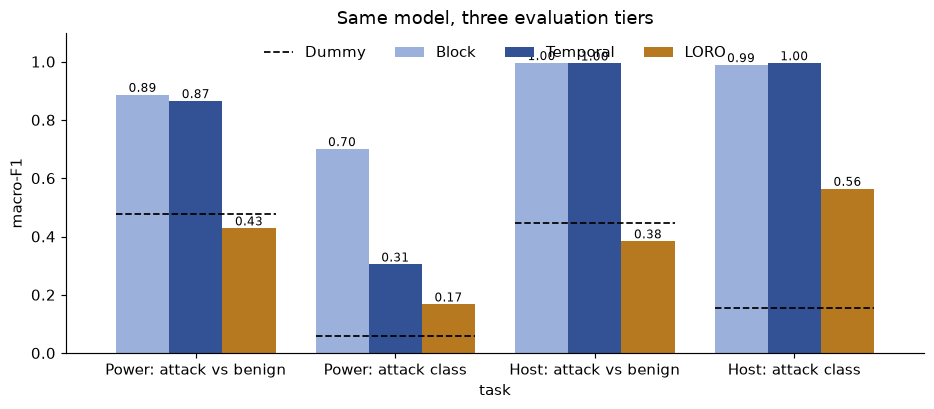

In [5]:
PT = {"Power: attack vs benign": (power, power[POWER_FEATS], power.is_attack.map({0:"benign",1:"attack"}), "power"),
      "Power: attack class":     (power, power[POWER_FEATS], power.group, "power"),
      "Host: attack vs benign":  (host,  X_host, host.is_attack.map({0:"benign",1:"attack"}), "host"),
      "Host: attack class":      (host,  X_host, host.group, "host")}
PER = {}
for task,(d,X,y,src) in PT.items():
    tr,te = blocked_split(y, d.row_no//BLOCK[src]);              evaluate(task,"Block",X,y,tr,te)
    tr,te = hybrid_split(y, d.rec, d.row_no);                    evaluate(task,"Temporal",X,y,tr,te,keep=True)
    PER[task] = loro(task, X, y, d.rec)
R = pd.DataFrame(RES)
H = R[R.model.isin(["RandomForest","Dummy"])].pivot_table(index="task",columns=["model","tier"],values="macro_F1")
H = pd.DataFrame({"Block":H[("RandomForest","Block")],"Temporal":H[("RandomForest","Temporal")],"LORO":H[("RandomForest","LORO")],"Dummy (temporal)":H[("Dummy","Temporal")]}).loc[list(PT)]
display(H.round(3).to_string())
ax = H[["Block","Temporal","LORO"]].plot.bar(figsize=(9,4),color=[GREY,BLUE,ORANGE],width=.8,rot=0)
for i,v in enumerate(H["Dummy (temporal)"]): ax.hlines(v,i-.4,i+.4,colors="k",linestyles="--",lw=1.2,label="Dummy" if i==0 else None)
ax.set_ylim(0,1.1); ax.set_ylabel("macro-F1"); ax.set_title("Same model, three evaluation tiers"); ax.legend(frameon=False,ncol=4,loc="upper center")
for c in ax.containers: ax.bar_label(c,fmt="%.2f",fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** scores fall as the split gets stricter. The strict tiers (Temporal, LORO) are the credible ones.

## 5. Model comparison (temporal holdout)

In [6]:
T = R[R.tier=="Temporal"][["task","model","accuracy","macro_F1","train_s","ms_per_row"]]
display(T.round(4).to_string(index=False))

'                   task        model  accuracy  macro_F1  train_s  ms_per_row\nPower: attack vs benign        Dummy    0.9156    0.4780      0.1      0.0002\nPower: attack vs benign       LogReg    0.7153    0.5676      0.3      0.0002\nPower: attack vs benign RandomForest    0.9602    0.8659      3.6      0.0071\n    Power: attack class        Dummy    0.1365    0.0600      0.1      0.0001\n    Power: attack class       LogReg    0.2994    0.2514      1.0      0.0005\n    Power: attack class RandomForest    0.2221    0.3051      3.9      0.0101\n Host: attack vs benign        Dummy    0.8091    0.4472      0.0      0.0036\n Host: attack vs benign       LogReg    0.3619    0.3617      0.4      0.0123\n Host: attack vs benign RandomForest    0.9970    0.9951      1.3      0.0345\n     Host: attack class        Dummy    0.4519    0.1556      0.0      0.0033\n     Host: attack class       LogReg    0.6643    0.7034      4.4      0.0110\n     Host: attack class RandomForest    0.9973    0

## 6. Confusion matrices (temporal holdout, Random Forest)

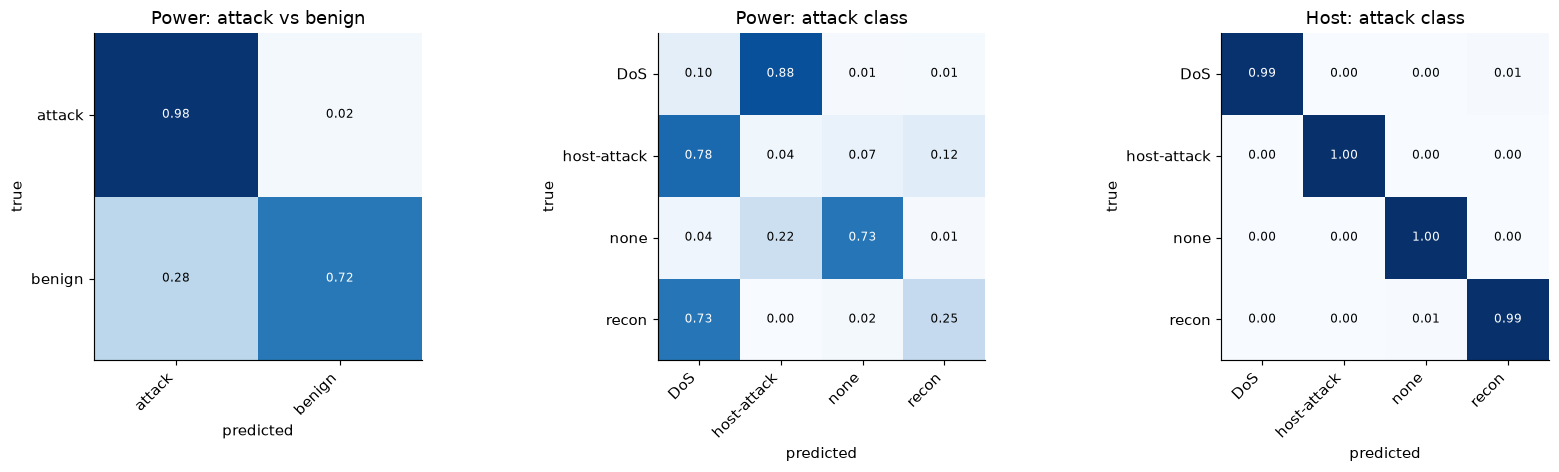

In [7]:
def cm_plot(a, key, title):
    s = STORE[key]; labs = sorted(set(s["y_true"])|set(s["y_pred"])); cm = confusion_matrix(s["y_true"], s["y_pred"], labels=labs, normalize="true")
    a.imshow(cm, vmin=0, vmax=1, cmap="Blues"); a.set_xticks(range(len(labs))); a.set_yticks(range(len(labs)))
    a.set_xticklabels(labs, rotation=45, ha="right"); a.set_yticklabels(labs); a.set_title(title); a.set_xlabel("predicted"); a.set_ylabel("true")
    for i in range(len(labs)):
        for j in range(len(labs)): a.text(j,i,f"{cm[i,j]:.2f}",ha="center",va="center",fontsize=8,color="white" if cm[i,j]>.5 else "black")
fig, axs = plt.subplots(1,3,figsize=(16,4.6))
for a,t in zip(axs,["Power: attack vs benign","Power: attack class","Host: attack class"]): cm_plot(a,(t,"Temporal"),t)
plt.tight_layout(); plt.show()

## 7. Does it generalise to a recording it never saw? (LORO)

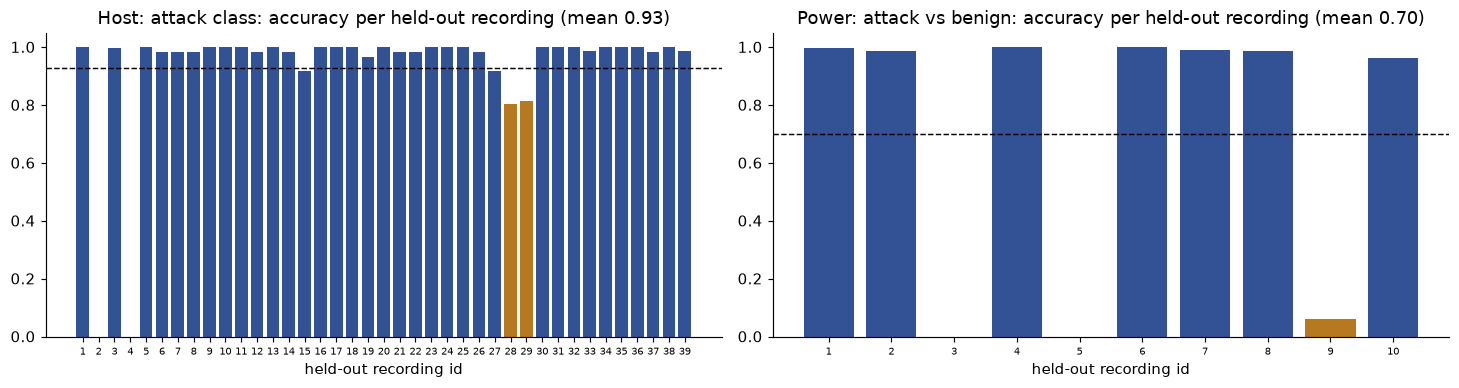

Held-out recordings with accuracy < 0.9:


,rec,true,rows,acc,task
0,2,none,1151,0.000,Host: attack class
1,4,none,1151,0.000,Host: attack class
2,28,DoS,61,0.803,Host: attack class
3,29,DoS,59,0.814,Host: attack class
4,3,benign,6947,0.000,Power: attack vs benign
5,5,benign,7416,0.000,Power: attack vs benign
6,9,attack,14172,0.060,Power: attack vs benign


In [8]:
fig, axs = plt.subplots(1,2,figsize=(14,3.8))
for a,t in zip(axs,["Host: attack class","Power: attack vs benign"]):
    d = PER[t]; a.bar(d.rec.astype(str), d.acc, color=[BLUE if x>=.9 else ORANGE for x in d.acc]); a.axhline(d.acc.mean(),ls="--",c="k",lw=1)
    a.set_ylim(0,1.05); a.set_title(f"{t}: accuracy per held-out recording (mean {d.acc.mean():.2f})"); a.set_xlabel("held-out recording id"); a.tick_params(axis="x",labelsize=7)
plt.tight_layout(); plt.show()
bad = pd.concat([PER[t].assign(task=t) for t in ["Host: attack class","Power: attack vs benign"]]).query("acc < 0.9")
print("Held-out recordings with accuracy < 0.9:"); display(bad.round(3).reset_index(drop=True) if len(bad) else "none")

## 8. Network flows: DoS vs recon, and unseen attack types

model,Dummy,LogReg,RandomForest
task,,,
netA: DoS vs recon (unseen files),0.291,0.696,0.941
netA: exact attack type (unseen files),0.008,0.383,0.350
netB: DoS vs recon (unseen files),0.370,0.998,1.000
netB: exact attack type (unseen files),0.006,0.485,0.324


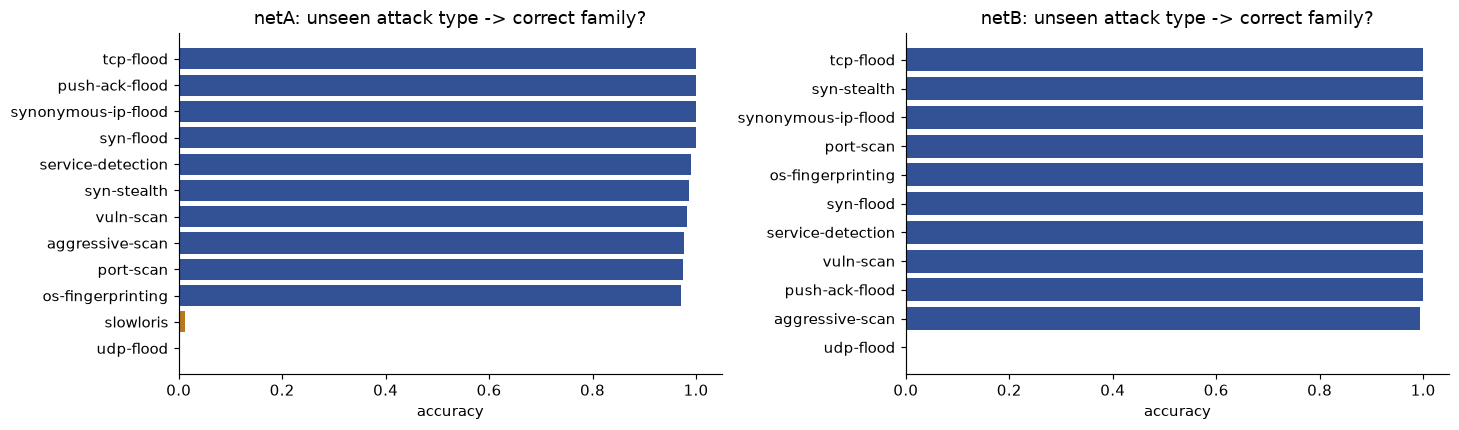

In [9]:
NR, LOAO = [], {}
for key,(df,feats) in net.items():
    keep = df.attack_norm.value_counts()[lambda s: s>=MIN_CLASS].index; d = df[df.attack_norm.isin(keep)].reset_index(drop=True)
    X = d[feats].replace([np.inf,-np.inf],np.nan); y = d.group.astype(str)
    tr,te = hybrid_split(y, d.source_file, d.row_no, tail_frac=0.3); evaluate(f"{key}: DoS vs recon (unseen files)","Temporal",X,y,tr,te,keep=True)
    ya = d.attack_norm
    tr,te = hybrid_split(ya, d.source_file, d.row_no);  evaluate(f"{key}: exact attack type (unseen files)","Temporal",X,ya,tr,te)
    rows=[]
    for atk in sorted(d.attack_norm.unique()):          # leave-one-attack-type-out
        t = (d.attack_norm==atk).values
        if (~t).sum()==0 or y[~t].nunique()<2: continue
        m = models(60)["RandomForest"].fit(X[~t], y[~t]); rows.append({"held_out_attack":atk,"true_group":y[t].iloc[0],"flows":int(t.sum()),"acc":float((m.predict(X[t])==y[t].values).mean())})
    LOAO[key] = pd.DataFrame(rows)
R = pd.DataFrame(RES); N = R[R.task.str.startswith("net") & (R.tier=="Temporal")].pivot_table(index="task",columns="model",values="macro_F1")[["Dummy","LogReg","RandomForest"]]
display(N.round(3))
fig, axs = plt.subplots(1,len(LOAO),figsize=(7*len(LOAO),4.2),squeeze=False)
for a,(key,d) in zip(axs[0],LOAO.items()):
    d = d.sort_values("acc"); a.barh(d.held_out_attack,d.acc,color=[ORANGE if x<.5 else BLUE for x in d.acc]); a.set_xlim(0,1.05)
    a.set_title(f"{key}: unseen attack type -> correct family?"); a.set_xlabel("accuracy")
plt.tight_layout(); plt.show()

**Takeaway:** the network model works as a *family-level* detector (DoS vs recon). Orange bars are attack types it fails to place correctly when never seen in training. It is not a sub-type identifier.

## 9. Anomaly detection (Isolation Forest trained on benign power only)

' ROC-AUC  PR-AUC  precision  recall  false-positive rate\n   0.782   0.972      0.988   0.359                0.049'

Threshold = 95th percentile of benign-train anomaly scores. An anomaly score is a supporting signal, not proof of attack.


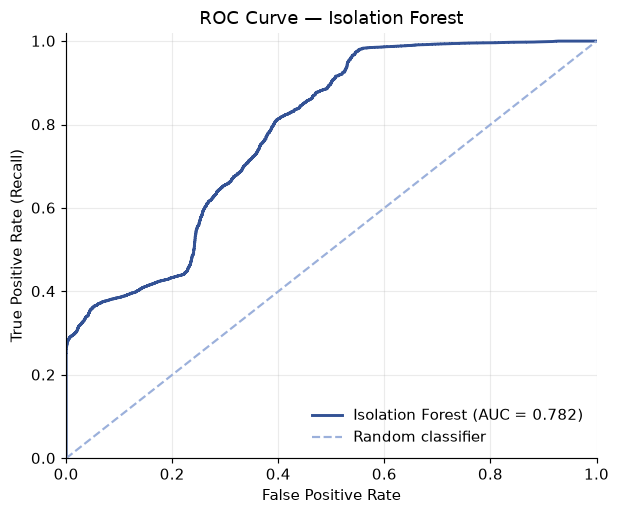

In [15]:
tr, te = hybrid_split(power.is_attack.map({0:"benign",1:"attack"}), power.rec, power.row_no)
Xb = power.iloc[tr].query("is_attack == 0")[POWER_FEATS]; sc = StandardScaler().fit(Xb)
iso = IsolationForest(n_estimators=200, random_state=SEED).fit(sc.transform(Xb))
s_te = -iso.score_samples(sc.transform(power.iloc[te][POWER_FEATS])); yt = power.iloc[te].is_attack.values
thr = np.percentile(-iso.score_samples(sc.transform(Xb)), 95); p = (s_te > thr).astype(int)
tp,fp,fn,tn = [int(v) for v in (((p==1)&(yt==1)).sum(),((p==1)&(yt==0)).sum(),((p==0)&(yt==1)).sum(),((p==0)&(yt==0)).sum())]
iso_res = pd.DataFrame([{"ROC-AUC":roc_auc_score(yt,s_te),"PR-AUC":average_precision_score(yt,s_te),"precision":tp/max(tp+fp,1),"recall":tp/max(tp+fn,1),"false-positive rate":fp/max(fp+tn,1)}])
display(iso_res.round(3).to_string(index=False))

print(
    "Threshold = 95th percentile of benign-train anomaly scores. "
    "An anomaly score is a supporting signal, not proof of attack."
)
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(yt, s_te)
auc = roc_auc_score(yt, s_te)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color=BLUE, lw=2, label=f"Isolation Forest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color=GREY, linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Isolation Forest")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right", frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. What the models rely on (top features)

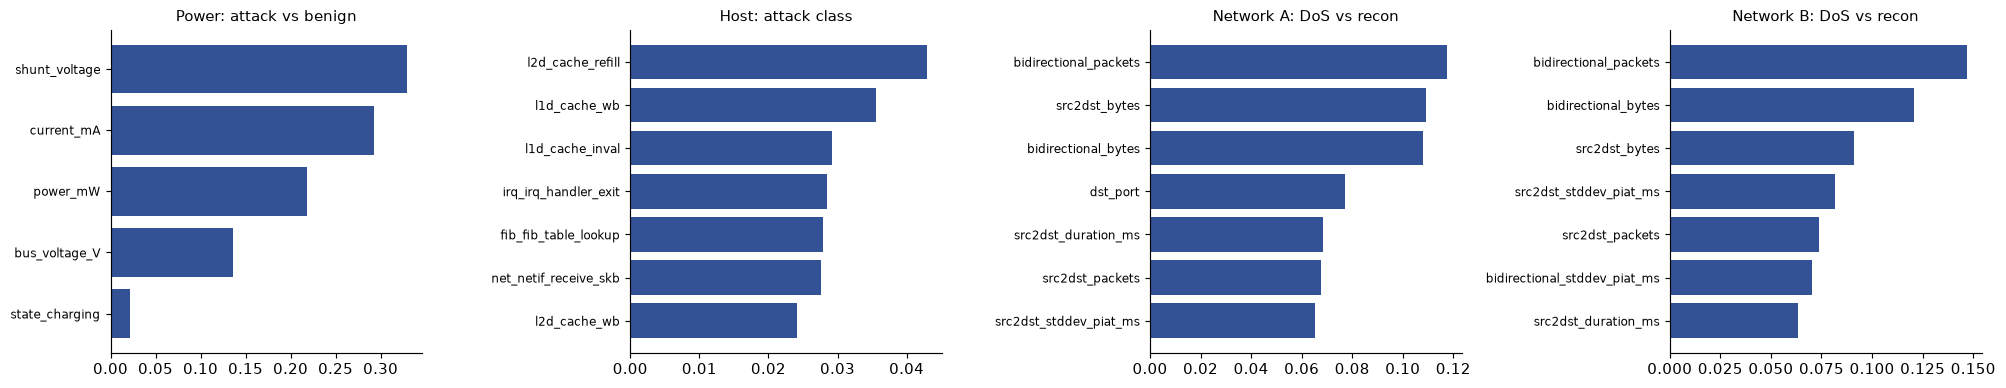

Feature importance shows what the model uses, not what causes an attack.


In [16]:
panels = [("Power: attack vs benign","Power: attack vs benign"),("Host: attack class","Host: attack class")] + [(f"{k}: DoS vs recon (unseen files)",f"Network {k[-1]}: DoS vs recon") for k in net]
fig, axs = plt.subplots(1,len(panels),figsize=(4.8*len(panels),3.8))
for a,(k,t) in zip(axs,panels):
    s = STORE[(k,"Temporal")]; imp = pd.Series(s["model"][-1].feature_importances_, index=s["cols"]).sort_values().tail(7)
    a.barh(imp.index, imp.values, color=BLUE); a.set_title(t, fontsize=10); a.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show(); print("Feature importance shows what the model uses, not what causes an attack.")

## 11. Findings (generated from the numbers above)

In [17]:
f = lambda t,tier: H.loc[t,tier]
lines = [
 f"Host attack class: macro-F1 {f('Host: attack class','Temporal'):.2f} (temporal) and {f('Host: attack class','LORO'):.2f} (LORO), Dummy {f('Host: attack class','Dummy (temporal)'):.2f}.",
 f"Power attack vs benign: macro-F1 {f('Power: attack vs benign','Temporal'):.2f} (temporal) and {f('Power: attack vs benign','LORO'):.2f} (LORO); power attack class: {f('Power: attack class','Temporal'):.2f} / {f('Power: attack class','LORO'):.2f}.",
 "Network DoS-vs-recon macro-F1 (unseen files, RF): " + ", ".join(f"{i.split(':')[0]} {N.loc[i,'RandomForest']:.2f}" for i in N.index if "DoS" in i) + ".",
 "Unseen attack types placed in correct family (acc >= 0.9): " + ", ".join(f"{k} {int((d.acc>=.9).sum())}/{len(d)}" for k,d in LOAO.items()) + ".",
 f"Isolation Forest (benign-only power): precision {iso_res['precision'][0]:.2f}, recall {iso_res['recall'][0]:.2f}, ROC-AUC {iso_res['ROC-AUC'][0]:.2f}.",
]
print("\n".join("• "+l for l in lines))

• Host attack class: macro-F1 1.00 (temporal) and 0.56 (LORO), Dummy 0.16.
• Power attack vs benign: macro-F1 0.87 (temporal) and 0.43 (LORO); power attack class: 0.31 / 0.17.
• Network DoS-vs-recon macro-F1 (unseen files, RF): netA 0.94, netB 1.00.
• Unseen attack types placed in correct family (acc >= 0.9): netA 10/12, netB 10/11.
• Isolation Forest (benign-only power): precision 0.99, recall 0.36, ROC-AUC 0.78.
